# Recurrent SLDS
A Recurrent Switching Linear Dynamical System (rSLDS) is a generalization of a Switching Linear Dynamical System (SLDS) in which the switches in the discrete state are allowed to depend on the value of the continuous state (hence the name recurrent). The rSLDS was developed by Linderman _et al_ in ["Bayesian Learning and Inference in Recurrent Switching Linear Dynamical Systems"](http://proceedings.mlr.press/v54/linderman17a.html).

In this notebook, we'll give an example of fitting an rSLDS from data, and show that it can learn globally non-linear dynamics. We will focus on using an rSLDS in the context of Dynamax, and so will skip most of the implementation-level details. For more information on implementation, see the paper above.


## 1. Generative model for rSLDS
The generative model for rSLDS is the same as the SLDS case, except that the discrete state transition probabilities are modulated by the continuous state.

1. **Discrete State Update**. At each time step, sample a new discrete state $z_t \mid z_{t-1}, x_{t-1}$ with probabilities driven by a logistic regression on the continuous state: 

   $$
   p(z_t = j \mid z_{t-1} = i, x_{t-1}) \propto
   \exp{\left( R_{ij} + W_j^T x_{t-1} + V_j^T u_t \right)}
   $$
   where $R$ is a matrix of transition logits and $V_j$ is a vector of weights associated with discrete state $j$, that control dependence on an external, known input $u_t$. $W_j$ is again a vector of weights associated with state $j$, which weights the contribution from the prior state.

2. **Continuous State Update**. Update the state using the dynamics matrix corresponding to the new discrete state:

   $$
   x_t = F_k x_{t-1} + B_k u_{t} + b_k + w_t
   $$
   $F_k$ is the dynamics matrix corresponding to discrete state $k$. $u_t$ is the input vector (specified by the user, not inferred by Dynamax) and $B_k$ is the corresponding control matrix. The vector $b_k$ is an offset vector, which can drive the dynamics in a particular direction. 
   The term $w_t$ is a noise term, which perturbs the dynamics. 
   Most commonly these are modeled as zero-mean multivariate Gaussians, which is what Dynamax's `RecurrentGaussianSLDS` assumes.

3. **Emission**. We now make an observation of the state, according to the specified observation model. In the general case, the state controls the observation via a Generalized Linear Model:

   $$
   y_t \sim \mathcal{P}(\eta(H_k x_t + d_k + D_k u_t + v_t))
   $$
   $\mathcal{P}$ is a probability distribution. The inner arguments form an affine measurement of the state, which is then passed through the inverse link function $\eta(\cdot)$.
   In this case, $H_k$ is the measurement matrix corresponding to discrete state $k$, $d_k$ is an offset or bias term corresponding to discrete state $k$, $D_k$ is called the feedthrough matrix or passthrough matrix (it passes the input directly to the emission). In the Gaussian case, the emission can simply be written as $y_t = H_k x_t + d_k + D_k u_t + v_t$ where $v_t$ is a Gaussian r.v. `RecurrentGaussianSLDS` implements this Gaussian case.
   

In [1]:
%%capture
try:
    import dynamax
except ModuleNotFoundError:
    print('installing dynamax')
    %pip install -q dynamax[notebooks]
    import dynamax

In [2]:
import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np
key = jr.PRNGKey(12345)

import matplotlib.pyplot as plt
from matplotlib import gridspec
%matplotlib inline

import seaborn as sns
color_names = ["windows blue", "red", "amber", "faded green"]
colors = sns.xkcd_palette(color_names)
sns.set_style("white")
sns.set_context("talk")

from dynamax.slds import RecurrentGaussianSLDS
from dynamax.utils.utils import random_rotation, find_permutation

# Helper functions for plotting results
def plot_trajectory(z, x, ax=None, ls="-"):
    zcps = np.concatenate(([0], np.where(np.diff(z))[0] + 1, [z.size]))
    if ax is None:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.gca()
    for start, stop in zip(zcps[:-1], zcps[1:]):
        ax.plot(x[start:stop + 1, 0],
                x[start:stop + 1, 1],
                lw=1, ls=ls,
                color=colors[z[start] % len(colors)],
                alpha=1.0)
    return ax

def plot_observations(z, y, ax=None, ls="-", lw=1):

    zcps = np.concatenate(([0], np.where(np.diff(z))[0] + 1, [z.size]))
    if ax is None:
        fig = plt.figure(figsize=(4, 4))
        ax = fig.gca()
    T, N = y.shape
    t = np.arange(T)
    for n in range(N):
        for start, stop in zip(zcps[:-1], zcps[1:]):
            ax.plot(t[start:stop + 1], y[start:stop + 1, n],
                    lw=lw, ls=ls,
                    color=colors[z[start] % len(colors)],
                    alpha=1.0)
    return ax


def plot_most_likely_dynamics(model, params,
    xlim=(-4, 4), ylim=(-3, 3), nxpts=20, nypts=20,
    alpha=0.8, ax=None, figsize=(3, 3)):
    
    K = model.num_states
    assert model.state_dim == 2
    x = np.linspace(*xlim, nxpts)
    y = np.linspace(*ylim, nypts)
    X, Y = np.meshgrid(x, y)
    xy = np.column_stack((X.ravel(), Y.ravel()))

    # Get the probability of each state at each xy location
    z = np.argmax(xy.dot(params.transitions.recurrent_weights.T) + params.transitions.logits[0], axis=1)

    if ax is None:
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(111)

    for k, (F, b) in enumerate(zip(params.dynamics.weights, params.dynamics.biases)):
        dxydt_m = xy.dot(F.T) + b - xy

        zk = z == k
        if zk.sum(0) > 0:
            ax.quiver(xy[zk, 0], xy[zk, 1],
                      dxydt_m[zk, 0], dxydt_m[zk, 1],
                      color=colors[k % len(colors)], alpha=alpha)

    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')

    plt.tight_layout()

    return ax


# Helper function to permute the discrete states of a parameter set:
# state k of the result is state perm[k] of `params`
def permute(params, perm):
    initial = params.initial._replace(probs=params.initial.probs[perm])
    transitions = params.transitions._replace(logits=params.transitions.logits[:, perm],   # recurrent_only: one row
                                              recurrent_weights=params.transitions.recurrent_weights[perm],
                                              input_weights=params.transitions.input_weights[perm])
    dynamics = params.dynamics._replace(weights=params.dynamics.weights[perm],
                                        biases=params.dynamics.biases[perm],
                                        input_weights=params.dynamics.input_weights[perm],
                                        covs=params.dynamics.covs[perm])
    return params._replace(initial=initial, transitions=transitions, dynamics=dynamics)   # the single emission model is shared

## 2. Simulating Data from an rSLDS

Below, we create a simulated dataset from a non-linear system, which we'll call the "Nascar" dataset. The Nascar dataset is meant to emulate cars going around a track. There are 4 states total: 2 for driving along each straightaway, and two for semicircular turns at each end of the track.

You'll note that in creating the rSLDS we use **recurrent_only=True**. This means that the transition probabilities are determined only by the previous continuous state $x_{t-1}$ (and by the inputs, if present). There is no dependence on the previous discrete state $z_{t-1}$. Instead, each state simply has a constant bias $R_j$ which biases the transitions toward state $j$. This model is strictly less flexible than the full rSLDS formulation. By setting the weights on the continuous state to be very large, we make the discrete state transitions essentially deterministic. After creating the rSLDS and sampling a trajectory, we plot the true trajectory below.


In [3]:
# Global parameters
T = 10000
K = 4
D_obs = 10
D_latent = 2

In [4]:
# Simulate the "nascar" data
def make_nascar_model(key):
    k_rot1, k_rot2, k_init, k_H, k_d = jr.split(key, 5)
    Fs = [random_rotation(k_rot1, D_latent, np.pi/24.),
      random_rotation(k_rot2, D_latent, np.pi/48.)]

    # Set the center points for each system
    centers = [np.array([+2.0, 0.]),
           np.array([-2.0, 0.])]
    bs = [-(F - np.eye(D_latent)).dot(center) for F, center in zip(Fs, centers)]

    # Add a "right" state
    Fs.append(np.eye(D_latent))
    bs.append(np.array([+0.1, 0.]))

    # Add a "left" state
    Fs.append(np.eye(D_latent))
    bs.append(np.array([-0.25, 0.]))

    # Construct multinomial regression to divvy up the space
    w1, b1 = np.array([+1.0, 0.0]), np.array([-2.0])   # x + b > 0 -> x > -b
    w2, b2 = np.array([-1.0, 0.0]), np.array([-2.0])   # -x + b > 0 -> x < b
    w3, b3 = np.array([0.0, +1.0]), np.array([0.0])    # y > 0
    w4, b4 = np.array([0.0, -1.0]), np.array([0.0])    # y < 0
    Ws = np.vstack((100*w1, 100*w2, 10*w3,10*w4))
    R = np.concatenate((100*b1, 100*b2, 10*b3, 10*b4))
    
    true_rslds = RecurrentGaussianSLDS(K, D_latent, D_obs, 
                      recurrent_only=True,
                      dynamics_cov_type="diag",
                      single_subspace=True)
    # Set the remaining parameters: uniform initial state probabilities,
    # an orthogonal measurement matrix and standard normal biases
    true_params, _ = true_rslds.initialize(
        k_init,
        initial_params=dict(initial_probs=jnp.ones(K) / K),
        transition_params=dict(logits=jnp.array(R)[None], recurrent_weights=jnp.array(Ws)),
        dynamics_params=dict(initial_mean=jnp.array([0., 1.]), initial_cov=1e-4 * jnp.eye(D_latent),
                             weights=jnp.array(Fs), biases=jnp.array(bs), covs=1e-4 * jnp.ones((K, D_latent))),
        emission_params=dict(weights=jnp.linalg.svd(jr.normal(k_H, (1, D_obs, D_latent)), full_matrices=False)[0],
                             biases=jr.normal(k_d, (1, D_obs)),
                             covs=1e-2 * jnp.ones((1, D_obs))))
    return true_rslds, true_params

# Sample from the model
key, k_model, k_sample = jr.split(key, 3)
true_rslds, true_params = make_nascar_model(k_model)
z, x, y = true_rslds.sample(true_params, k_sample, T)

**Visualizing Trajectories**

We've defined some helper functions above to plot the latent state trajectories, and color code them according to the discrete state. In the left panel, we show the continuous state trajectories. In the right panel below, we show 3 of the observations over the first 1000 time steps (our observations are 10 dimensional, but we've plotted 3 observation traces to reduce clutter).

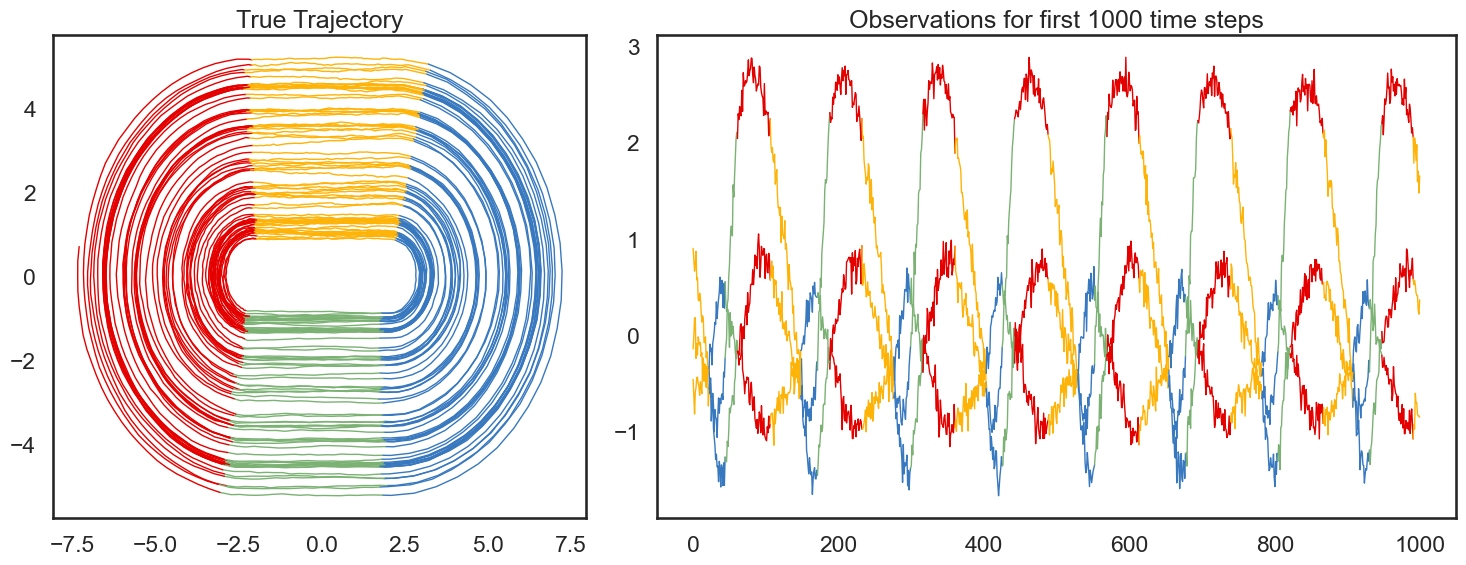

In [5]:
fig = plt.figure(figsize=(15, 6)) 
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 3]) 
ax0 = plt.subplot(gs[0])
plot_trajectory(z, x, ax=ax0)
plt.title("True Trajectory")

ax1 = plt.subplot(gs[1])
plot_observations(z[:1000], y[:1000,:3], ax=ax1)
plt.title("Observations for first 1000 time steps")
plt.tight_layout()

## 3. Exercise

### 3.1 Linear vs. Non-Linear Systems
It's worth looking at the plot of the trajectories and considering the following: what behavior does the latent state show that could not be captured by a single linear dynamical system?

### 3.2 Understanding the discrete state transitions
Let's look again at the form of the discrete state transition probabilities:

$$
p(z_t = j \mid z_{t-1} = i, x_{t-1}) \propto
\exp{\left( R_{ij} + W_j^T x_{t-1} + V_j^T u_t \right)}
$$

In this case, we have used **recurrent only** transitions, which means we replace the matrix of logits $R_{ij}$ with a single row of biases $R_j$. Since we don't have any external inputs here, we can also leave out the input terms:


$$
p(z_t = j \mid z_{t-1} = i, x_{t-1}) \propto
\exp{\left( R_j + W_j^T x_{t-1} \right)}
$$

What happens as the magnitude of the entries in $W_j$ becomes very large (compared to the entries of $W_{j'}$ for the other states)? Do the transitions become more or less random?  

## 4. Fitting an rSLDS
Below, we create a new rSLDS object and fit it to the data generated above (note that our new rSLDS will only have access to the observations $y$ and not the true states $z$ or $x$). 

### 4.1 Fitting Methods
The fitting methods available for the rSLDS are the same as those available for the SLDS. We've reproduced the section on fitting methods from the SLDS notebook below.

**Important Note:**  
 <span style="font-size:larger;">
Understanding the following section is not necessary to use Dynamax! _`fit_em` runs Laplace-EM with the structured mean-field posterior._
</span>

**Parameter Learning for rSLDS**  
Parameter learning in an rSLDS requires approximate methods. Dynamax implements Laplace-EM. We don't have the space to describe the method in detail here, but the Laplace Approximation is described in several sources, and a good reference for the context of state-space models is ["Estimating State and Parameters in state-space models of Spike Trains,"](https://pdfs.semanticscholar.org/a71e/bf112cabd47cc67284dc8c12ab7644195d60.pdf) a book chapter by Macke et al.  The specific method used in this notebook is described by ["Zoltowski et al (2020)"](https://arxiv.org/abs/2001.04571).

**Approximate Posterior Distributions**
When using approximate methods, we must choose the form of the distribution we use to approximate the posterior. Dynamax uses the structured mean-field posterior, which assumes that the joint distribution over the continuous and discrete latent states factors as follows. If $q(z,x \mid y)$ is the joint posterior of the discrete and continuous states given the data, we use the approximation $q(z,x \mid y) \approx q(z \mid y)q(x \mid y)$, where $q(z \mid y)$ is the posterior for a Markov chain.

**Calling `fit_em` in Dynamax**  
Dynamax's HMMs, linear Gaussian SSMs and SLDSs share the same general syntax for fitting a model from data: `initialize` returns the parameters and their properties, and `fit_em` updates them. The syntax is as follows:
```python
params, props = rslds.initialize(key, method="pca_arhmm", emissions=y)
params, elbos, posterior = rslds.fit_em(params, props, y,
                                        num_iters=..., return_posterior=True)
```
`method="pca_arhmm"` initializes the measurement model by PCA of the emissions, then fits an autoregressive HMM to the projected data (started from k-means) for the discrete chain and the dynamics. `fit_em` returns the objective of each iteration, the ELBO plus the log prior of the parameters, computed after its E-step and before its M-step, and, with `return_posterior=True`, the variational posterior of the last E-step. The damping of the parameter updates is set when the model is created; `damping=0.0` below turns it off. The measurement matrix of the fitted model is not constrained to be orthogonal like the true model's, so the model we fit is an rSLDS with unconstrained Gaussian emissions. Below, we fit using Laplace-EM and look at its convergence.


### 4.2 Getting the Inferred States
For every SLDS and rSLDS model in Dynamax, calling `fit_em` with `return_posterior=True` returns a tuple of `(params, elbos, posterior)`.  `elbos` is an array containing the ELBO plus the log prior of the parameters at each iteration, used to check the convergence of the fitting algorithm. `posterior` is a `PosteriorSLDS` object. The posterior object is used to get an estimate of the latent variables (in this case $x$ and $z$) for each time step.

Below, we use the lines:
```python
q_lem = jax.tree_util.tree_map(lambda a: a[0], q_lem)
xhat_lem = q_lem.continuous.smoothed_means
```

to get an estimate $\hat x$ of the continuous state over time. The reason for the index `[0]` is that `fit_em` returns the posterior with a leading batch axis, where each entry is the posterior for a given sequence. In this case, we only have a single sequence, so we get the first (and only) element of the batch.


In [6]:
# Fit an rSLDS with the PCA + ARHMM initialization, using Laplace-EM with a structured variational posterior
rslds = RecurrentGaussianSLDS(K, D_latent, D_obs,
             recurrent_only=True,
             dynamics_cov_type="diag",
             single_subspace=True,
             damping=0.0)
key, k_init = jr.split(key)
params, props = rslds.initialize(k_init, method="pca_arhmm", emissions=y)
params, q_elbos_lem, q_lem = rslds.fit_em(params, props, y, num_iters=100, return_posterior=True)
q_lem = jax.tree_util.tree_map(lambda a: a[0], q_lem)   # one sequence: drop the batch axis
xhat_lem = q_lem.continuous.smoothed_means
params = permute(params, find_permutation(z, rslds.most_likely_states(params, y, q_lem)))
zhat_lem = rslds.most_likely_states(params, y, q_lem)

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:14&lt;00:00]</div>

### 4.3 Checking Convergence
Below, we plot the ELBO obtained via Laplace-EM.

Text(0, 0.5, 'ELBO')

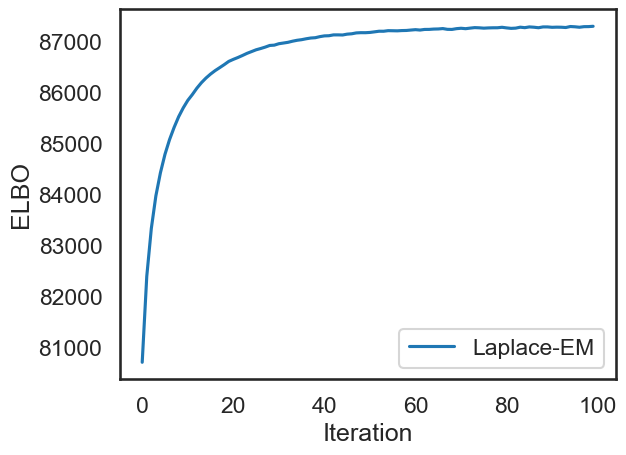

In [7]:
# Plot some results
plt.figure()
plt.plot(q_elbos_lem, label="Laplace-EM")
plt.legend()
plt.xlabel("Iteration")
plt.ylabel("ELBO")

## 5. Visualizing True and Inferred States
We wrote some helper functions above that plot a state trajectory, with different colors corresponding to the discrete latent states. **Note**: we only can recover the true system up to an affine transformation. That's why, even though we have permuted the discrete states to match the true system, the colors don't always match up.

In the cell immediately below, we see that the estimated latent trajectories found using Laplace-EM match the ground-truth. In the cell below that, we extract the dynamics matrices $F_k$s and use them to plot the system dynamics in each state.

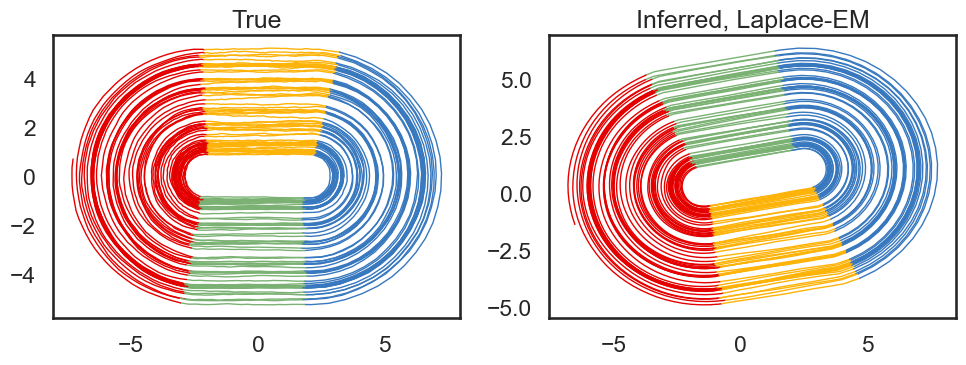

In [8]:
plt.figure(figsize=[10,4])
ax1 = plt.subplot(121)
plot_trajectory(z, x, ax=ax1)
plt.title("True")
ax2 = plt.subplot(122)
plot_trajectory(zhat_lem, xhat_lem, ax=ax2)
plt.title("Inferred, Laplace-EM")
plt.tight_layout()

Text(0.5, 1.0, 'Inferred Dynamics, Laplace-EM')

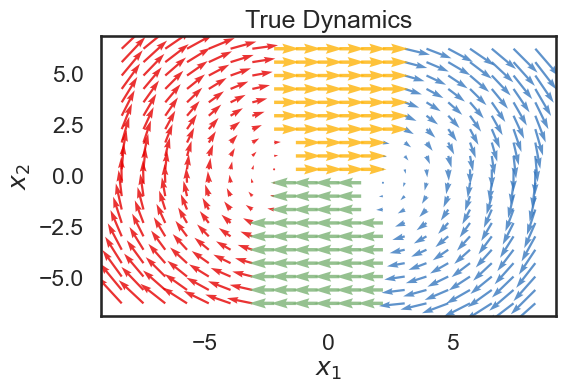

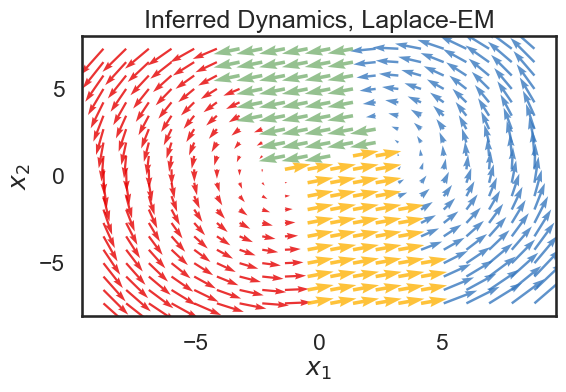

In [9]:
plt.figure(figsize=(6,4))
ax = plt.subplot(111)
lim = abs(x).max(axis=0) + 1
plot_most_likely_dynamics(true_rslds, true_params, xlim=(-lim[0], lim[0]), ylim=(-lim[1], lim[1]), ax=ax)
plt.title("True Dynamics")

plt.figure(figsize=(6,4))
ax = plt.subplot(111)
lim = abs(xhat_lem).max(axis=0) + 1
plot_most_likely_dynamics(rslds, params, xlim=(-lim[0], lim[0]), ylim=(-lim[1], lim[1]), ax=ax)
plt.title("Inferred Dynamics, Laplace-EM")